# Probability for computer engineering, derived from the physics

Every random variable here comes from hardware: photons arriving at a receiver, thermal noise in
a resistor, bits flipping in a packet, electrons filling states in a semiconductor. Each one is
**derived with calculus** (SymPy), **simulated** (NumPy Monte Carlo), and **proved** in Lean where
the statement is general.

| # | Physics | Probability | Lean |
|---|---|---|---|
| 1 | photons / bit errors | Binomial → Poisson, mean = variance | `binomial_sum_one` |
| 2 | bits in a packet | P(packet error) ≤ n p | `packet_union_bound` |
| 3 | shot noise, `np.var` | Var = E[X²] − E[X]² | `variance_identity` |
| 4 | worst-case guarantees | Markov's inequality | `markov_finite` |
| 5 | packet arrivals, decay | exponential is memoryless | `memoryless` |
| 6 | Johnson noise → BER | Gaussian tail integral | (SymPy) |
| 7 | semiconductors | Fermi-Dirac symmetry | `fermi_symmetry` |

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
import numpy as np, sympy as sp, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
sp.init_printing(use_unicode=True)
from dgs import probability_ce as P

In [2]:
%load_ext dgs.lean_magic
%lean_reset

Lean cells cleared.


In [3]:
%%lean header
/-
Probability for computer engineering, from the physics of the hardware. Lean 4 + Mathlib.
Companion to notebooks/probability_computer_engineering.ipynb and dgs/probability_ce.py.

What is proved here:
  1. Binomial bit errors: the probabilities C(n,k) p^k (1-p)^(n-k) add up to 1
  2. Union bound for a packet: 1 - (1-p)^n <= n p (Bernoulli's inequality)
  3. Variance identity: sum w (x - mu)^2 = sum w x^2 - mu^2 (what np.var computes)
  4. Markov's inequality for a finite distribution: a P(X >= a) <= E[X]
  5. Exponential arrivals are memoryless: e^(-l(s+t)) / e^(-l s) = e^(-l t)
  6. Fermi-Dirac symmetry: f(x) + f(-x) = 1 with f(x) = 1 / (1 + e^x)

Check with (from a Lake project that depends on Mathlib):
    lake env lean ProbabilityCE.lean
-/
import Mathlib.Algebra.BigOperators.Field
import Mathlib.Algebra.Order.Chebyshev
import Mathlib.Analysis.SpecialFunctions.Exp
import Mathlib.Tactic.FieldSimp
import Mathlib.Tactic.Linarith
import Mathlib.Tactic.Ring

namespace ProbCE

**Lean cell `header`** (collected; compiled by `%lean_check`)
```lean
/-
Probability for computer engineering, from the physics of the hardware. Lean 4 + Mathlib.
Companion to notebooks/probability_computer_engineering.ipynb and dgs/probability_ce.py.

What is proved here:
  1. Binomial bit errors: the probabilities C(n,k) p^k (1-p)^(n-k) add up to 1
  2. Union bound for a packet: 1 - (1-p)^n <= n p (Bernoulli's inequality)
  3. Variance identity: sum w (x - mu)^2 = sum w x^2 - mu^2 (what np.var computes)
  4. Markov's inequality for a finite distribution: a P(X >= a) <= E[X]
  5. Exponential arrivals are memoryless: e^(-l(s+t)) / e^(-l s) = e^(-l t)
  6. Fermi-Dirac symmetry: f(x) + f(-x) = 1 with f(x) = 1 / (1 + e^x)

Check with (from a Lake project that depends on Mathlib):
    lake env lean ProbabilityCE.lean
-/
import Mathlib.Algebra.BigOperators.Field
import Mathlib.Algebra.Order.Chebyshev
import Mathlib.Analysis.SpecialFunctions.Exp
import Mathlib.Tactic.FieldSimp
import Mathlib.Tactic.Linarith
import Mathlib.Tactic.Ring

namespace ProbCE
```

## 1. Counting photons: Binomial → Poisson

Split one bit slot into n tiny time pieces; each holds a photon with probability λ/n. The count
is Binomial(n, λ/n). As n → ∞, C(n,k)/nᵏ → 1/k! and (1 − λ/n)ⁿ → e^{−λ}, giving Poisson(λ).
Summing the series gives mean = variance = λ, so the signal-to-noise ratio of a photon count is
λ/√λ = √λ (**shot noise**). Bit errors in a long stream follow the same limit.

In [4]:
pmf, limit = P.binomial_to_poisson()
display(pmf, sp.Eq(sp.Symbol("limit"), limit))
mean, var = P.poisson_moments()
print("Poisson mean =", mean, "  variance =", var)
N = P.photons_per_bit(1e-6, 10e9, 1550e-9)
print(f"1 uW at 10 Gb/s, 1550 nm: {N:.0f} photons per bit, shot-noise SNR = {P.shot_noise_snr(N):.1f}")

Poisson mean = lambda   variance = lambda
1 uW at 10 Gb/s, 1550 nm: 780 photons per bit, shot-noise SNR = 27.9


In [5]:
%%lean binomial
/-! ## 1. Binomial probabilities sum to 1 -/

theorem binomial_sum_one (p : ℝ) (n : ℕ) :
    ∑ k ∈ Finset.range (n + 1), p ^ k * (1 - p) ^ (n - k) * (n.choose k : ℝ) = 1 := by
  rw [← add_pow]
  simp

**Lean cell `binomial`** (collected; compiled by `%lean_check`)
```lean
/-! ## 1. Binomial probabilities sum to 1 -/

theorem binomial_sum_one (p : ℝ) (n : ℕ) :
    ∑ k ∈ Finset.range (n + 1), p ^ k * (1 - p) ^ (n - k) * (n.choose k : ℝ) = 1 := by
  rw [← add_pow]
  simp
```

## 2. A packet of n bits

P(no error) = (1 − p)ⁿ, so P(packet error) = 1 − (1 − p)ⁿ. Bernoulli's inequality bounds it by np:
the **union bound** engineers use for quick link budgets. Lean proves it for every n and p ≤ 1.

In [6]:
for p in (1e-6, 1e-4, 1e-3):
    exact, bound = P.packet_error(p, 1500)
    print(f"p = {p:g}: exact {exact:.4g}, bound n p = {bound:.4g}")

p = 1e-06: exact 0.001499, bound n p = 0.0015
p = 0.0001: exact 0.1393, bound n p = 0.15
p = 0.001: exact 0.777, bound n p = 1


In [7]:
%%lean union
/-! ## 2. Union bound for a packet of n bits -/

theorem packet_union_bound (p : ℝ) (n : ℕ) (hp1 : p ≤ 1) :
    1 - (1 - p) ^ n ≤ n * p := by
  have h := one_add_mul_le_pow (show (-2 : ℝ) ≤ -p by linarith) n
  rw [← sub_eq_add_neg] at h
  linarith

**Lean cell `union`** (collected; compiled by `%lean_check`)
```lean
/-! ## 2. Union bound for a packet of n bits -/

theorem packet_union_bound (p : ℝ) (n : ℕ) (hp1 : p ≤ 1) :
    1 - (1 - p) ^ n ≤ n * p := by
  have h := one_add_mul_le_pow (show (-2 : ℝ) ≤ -p by linarith) n
  rw [← sub_eq_add_neg] at h
  linarith
```

## 3–4. Variance and Markov's inequality

Var = Σ w(x − μ)² = Σ wx² − μ² is what `np.var` computes. Markov's inequality, P(X ≥ a) ≤ E[X]/a,
needs only X ≥ 0, so it is a worst-case guarantee with no distribution assumed (Chebyshev is
Markov applied to (X − μ)²).

In [8]:
%%lean variance
/-! ## 3. Variance identity -/

theorem variance_identity {n : ℕ} (w x : Fin n → ℝ) (hw : ∑ i, w i = 1) (μ : ℝ)
    (hμ : μ = ∑ i, w i * x i) :
    ∑ i, w i * (x i - μ) ^ 2 = ∑ i, w i * x i ^ 2 - μ ^ 2 := by
  have h : ∀ i, w i * (x i - μ) ^ 2 = w i * x i ^ 2 - 2 * μ * (w i * x i) + μ ^ 2 * w i :=
    fun i => by ring
  simp only [h, Finset.sum_add_distrib, Finset.sum_sub_distrib, ← Finset.mul_sum, hw, ← hμ]
  ring

**Lean cell `variance`** (collected; compiled by `%lean_check`)
```lean
/-! ## 3. Variance identity -/

theorem variance_identity {n : ℕ} (w x : Fin n → ℝ) (hw : ∑ i, w i = 1) (μ : ℝ)
    (hμ : μ = ∑ i, w i * x i) :
    ∑ i, w i * (x i - μ) ^ 2 = ∑ i, w i * x i ^ 2 - μ ^ 2 := by
  have h : ∀ i, w i * (x i - μ) ^ 2 = w i * x i ^ 2 - 2 * μ * (w i * x i) + μ ^ 2 * w i :=
    fun i => by ring
  simp only [h, Finset.sum_add_distrib, Finset.sum_sub_distrib, ← Finset.mul_sum, hw, ← hμ]
  ring
```

In [9]:
%%lean markov
/-! ## 4. Markov's inequality -/

theorem markov_finite {n : ℕ} (w X : Fin n → ℝ) (a : ℝ) (hw : ∀ i, 0 ≤ w i) (hX : ∀ i, 0 ≤ X i) :
    a * ∑ i, (if a ≤ X i then w i else 0) ≤ ∑ i, w i * X i := by
  rw [Finset.mul_sum]
  apply Finset.sum_le_sum
  intro i _
  split_ifs with h
  · nlinarith [hw i]
  · simp only [mul_zero]
    exact mul_nonneg (hw i) (hX i)

**Lean cell `markov`** (collected; compiled by `%lean_check`)
```lean
/-! ## 4. Markov's inequality -/

theorem markov_finite {n : ℕ} (w X : Fin n → ℝ) (a : ℝ) (hw : ∀ i, 0 ≤ w i) (hX : ∀ i, 0 ≤ X i) :
    a * ∑ i, (if a ≤ X i then w i else 0) ≤ ∑ i, w i * X i := by
  rw [Finset.mul_sum]
  apply Finset.sum_le_sum
  intro i _
  split_ifs with h
  · nlinarith [hw i]
  · simp only [mul_zero]
    exact mul_nonneg (hw i) (hX i)
```

## 5. Exponential arrival times are memoryless

Poisson arrivals (photons, packets, radioactive decays) have exponential waiting times with
P(T > t) = e^{−λt}. Having already waited s tells you nothing: P(T > s + t | T > s) = P(T > t).
This is why queueing models of routers and caches are tractable.

In [10]:
print("P(T > s+t | T > s) - P(T > t) =", P.memoryless())
print("expected transmissions with failure prob q:", P.expected_transmissions())

P(T > s+t | T > s) - P(T > t) = 0


expected transmissions with failure prob q: -1/(q - 1)


In [11]:
%%lean memoryless
/-! ## 5. Exponential waiting times are memoryless -/

theorem memoryless (l s t : ℝ) :
    Real.exp (-l * (s + t)) / Real.exp (-l * s) = Real.exp (-l * t) := by
  rw [div_eq_iff (Real.exp_pos _).ne', ← Real.exp_add]
  ring_nf

**Lean cell `memoryless`** (collected; compiled by `%lean_check`)
```lean
/-! ## 5. Exponential waiting times are memoryless -/

theorem memoryless (l s t : ℝ) :
    Real.exp (-l * (s + t)) / Real.exp (-l * s) = Real.exp (-l * t) := by
  rw [div_eq_iff (Real.exp_pos _).ne', ← Real.exp_add]
  ring_nf
```

## 6. Thermal noise → bit error rate

A resistor at temperature T produces Gaussian noise with σ = √(4kTRB). Send +A or −A and decide
by sign. An error on +A happens when the noise is below −A, so BER = ∫_{−∞}^{−A} (Gaussian pdf) dx.

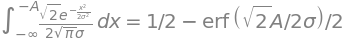

Johnson noise, 1 kOhm, 300 K, 1 MHz: sigma = 4.07 uV


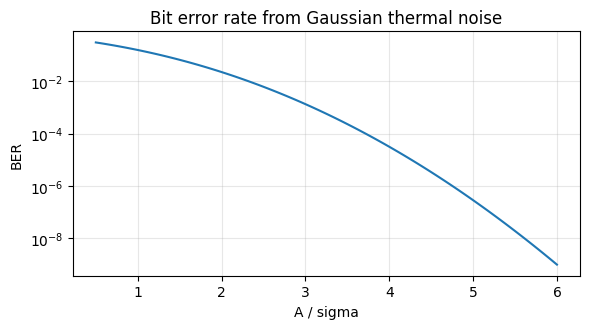

In [12]:
integral, closed = P.ber_derivation()
display(sp.Eq(integral, closed))
print(f"Johnson noise, 1 kOhm, 300 K, 1 MHz: sigma = {P.johnson_sigma(300, 1e3, 1e6) * 1e6:.2f} uV")
snr = np.linspace(0.5, 6, 100)
plt.figure(figsize=(6, 3.4)); plt.semilogy(snr, [P.ber(a, 1) for a in snr])
plt.xlabel("A / sigma"); plt.ylabel("BER"); plt.title("Bit error rate from Gaussian thermal noise"); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Fermi-Dirac occupancy in a semiconductor

f(E) = 1/(1 + e^{(E−μ)/kT}). A state x above μ is full exactly as often as a state x below μ is
empty: f(μ + x) + f(μ − x) = 1. This symmetry is why electron and hole populations mirror each other
around the Fermi level.

f(x) + f(-x) - 1 = 0


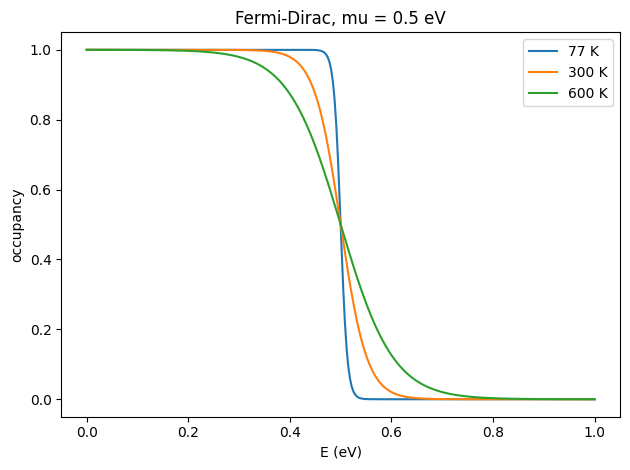

In [13]:
print("f(x) + f(-x) - 1 =", P.fermi_symmetry())
E = np.linspace(0, 1, 300)
for T in (77, 300, 600):
    plt.plot(E, P.fermi(E, 0.5, T), label=f"{T} K")
plt.xlabel("E (eV)"); plt.ylabel("occupancy"); plt.legend(); plt.title("Fermi-Dirac, mu = 0.5 eV")
plt.tight_layout(); plt.show()

In [14]:
%%lean fermi
/-! ## 6. Fermi-Dirac symmetry -/

theorem fermi_symmetry (x : ℝ) : 1 / (1 + Real.exp x) + 1 / (1 + Real.exp (-x)) = 1 := by
  have h1 : 0 < 1 + Real.exp x := by positivity
  have h2 : Real.exp (-x) = 1 / Real.exp x := by rw [Real.exp_neg, one_div]
  rw [h2]
  have hx : 0 < Real.exp x := Real.exp_pos x
  field_simp
  ring

**Lean cell `fermi`** (collected; compiled by `%lean_check`)
```lean
/-! ## 6. Fermi-Dirac symmetry -/

theorem fermi_symmetry (x : ℝ) : 1 / (1 + Real.exp x) + 1 / (1 + Real.exp (-x)) = 1 := by
  have h1 : 0 < 1 + Real.exp x := by positivity
  have h2 : Real.exp (-x) = 1 / Real.exp x := by rw [Real.exp_neg, one_div]
  rw [h2]
  have hx : 0 < Real.exp x := Real.exp_pos x
  field_simp
  ring
```

## 8. Monte Carlo: every formula against a simulation

In [15]:
rows = P.monte_carlo()
display(pd.DataFrame(rows, index=["formula", "simulated"]).T)

,formula,simulated
"BER, A/sigma = 2.5",0.006210,0.006132
photon count mean (binomial n=1e4),7.000000,7.003158
photon count variance,7.000000,7.010623
"packet error, 1500 bits, p = 1e-4",0.139298,0.139543
"E[transmissions], q = 0.3",1.428571,1.426740
P(T > 3 | T > 1) vs P(T > 2),0.367725,0.367322
Markov: P(X >= 3) <= E[X]/3,0.333333,0.049543
CLT: std of sum of 12 uniforms - 6,1.000000,1.001862


## 9. Compile every Lean cell

In [16]:
%%lean footer
end ProbCE

**Lean cell `footer`** (collected; compiled by `%lean_check`)
```lean
end ProbCE
```

In [17]:
lean_result = %lean_check
from dgs.lean_magic import SESSION
display(pd.DataFrame({"Lean theorem": SESSION.last.theorems, "status": SESSION.last.status}))

Lean status: VERIFIED  (lake env lean exit 0, no errors, no sorry), 10 s


,Lean theorem,status
0,binomial_sum_one,VERIFIED
1,packet_union_bound,VERIFIED
2,variance_identity,VERIFIED
3,markov_finite,VERIFIED
4,memoryless,VERIFIED
5,fermi_symmetry,VERIFIED
